In [2]:
import pandas as pd
import psycopg

# Connection string with your local database credentials
conn_str = "dbname=onor user=postgres password=onor123 host=localhost port=5432"


In [3]:
# Connect and load the table into a pandas DataFrame
with psycopg.connect(conn_str) as conn:
    df = pd.read_sql("SELECT * FROM journalistic_institutions;", conn)

# Display the first few rows
df.head()

C:\Users\a11\AppData\Local\Temp\ipykernel_10156\528559180.py:3: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql("SELECT * FROM journalistic_institutions;", conn)


,id,institution_name,country,medium_type,founded_year,website_url,publications_since_2020,created_at
0,1,The New York Times,United States,Newspaper,1851,https://nytimes.com,620000,2026-10-03 14:22:11.714540+00:00
1,2,BBC News,United Kingdom,Broadcast,1922,https://bbc.com/news,850000,2026-10-03 14:22:11.714540+00:00
2,3,Reuters,United Kingdom,News Agency,1851,https://reuters.com,1100000,2026-10-03 14:22:11.714540+00:00
3,4,Associated Press,United States,News Agency,1846,https://apnews.com,1250000,2026-10-03 14:22:11.714540+00:00
4,5,Der Spiegel,Germany,Magazine,1947,https://spiegel.de,185000,2026-10-03 14:22:11.714540+00:00


C:\Users\a11\AppData\Local\Temp\ipykernel_10156\1571362035.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='medium_type', ax=axes[0, 0], palette='Set2')
C:\Users\a11\AppData\Local\Temp\ipykernel_10156\1571362035.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df, x='country', y='publications_since_2020', ax=axes[0, 1], palette='Blues_d')


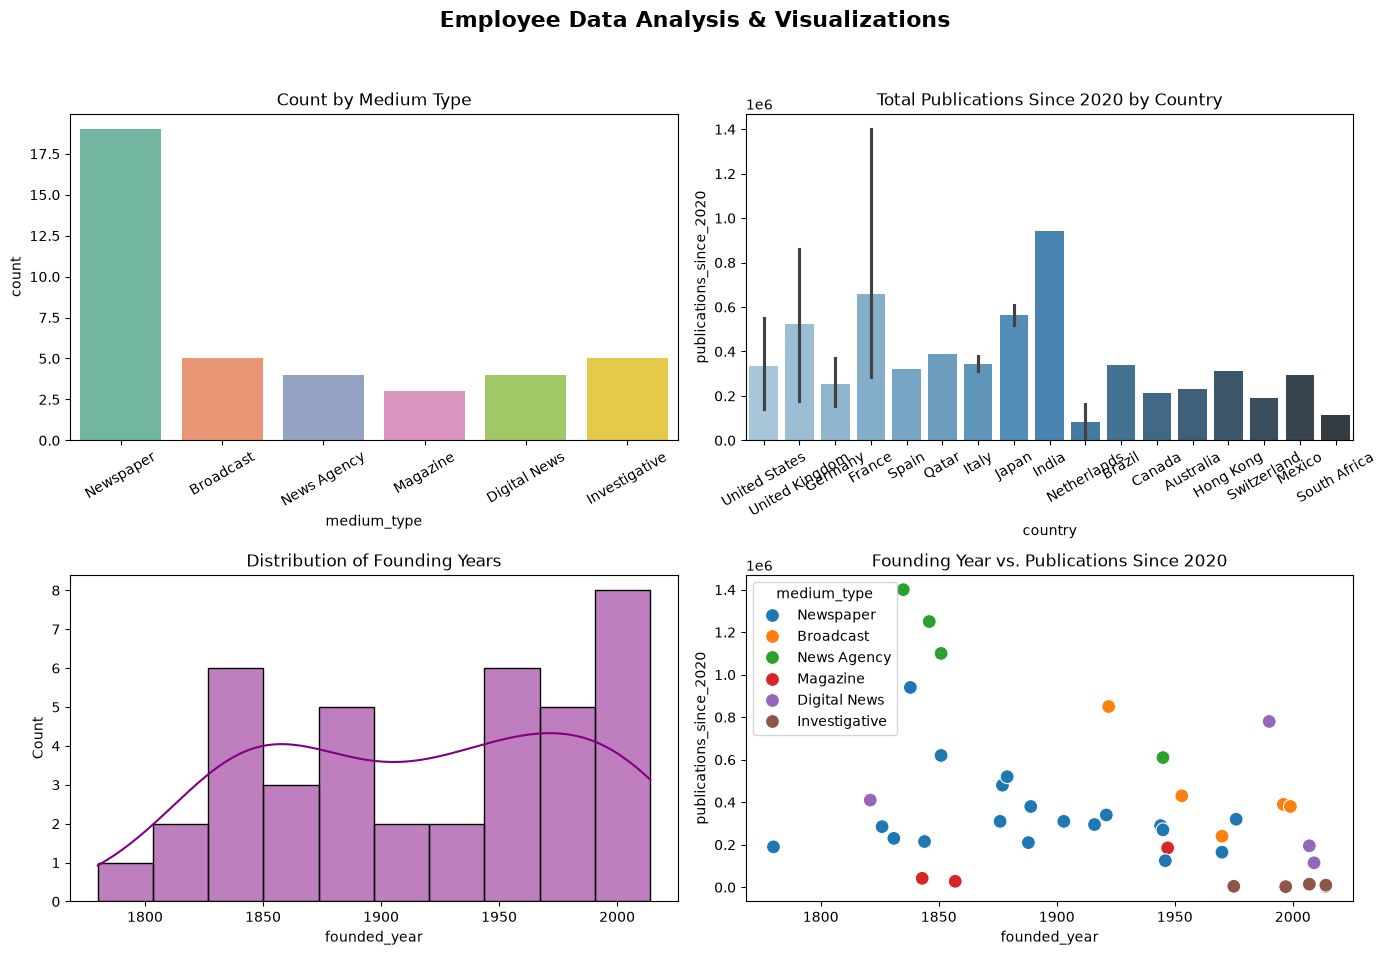

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns

# 2. Create a 2x2 grid for multiple diagrams
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle("Employee Data Analysis & Visualizations", fontsize=16, fontweight='bold')

# Diagram 1: Count of institutions by medium type (Bar Chart)
if 'medium_type' in df.columns:
    sns.countplot(data=df, x='medium_type', ax=axes[0, 0], palette='Set2')
    axes[0, 0].set_title("Count by Medium Type")
    axes[0, 0].tick_params(axis='x', rotation=30)

# Diagram 2: Total publications since 2020 by country (Bar Chart)
if 'country' in df.columns and 'publications_since_2020' in df.columns:
    sns.barplot(data=df, x='country', y='publications_since_2020', ax=axes[0, 1], palette='Blues_d')
    axes[0, 1].set_title("Total Publications Since 2020 by Country")
    axes[0, 1].tick_params(axis='x', rotation=30)

# Diagram 3: Distribution of founding years (Histogram)
if 'founded_year' in df.columns:
    sns.histplot(data=df, x='founded_year', bins=10, kde=True, ax=axes[1, 0], color='purple')
    axes[1, 0].set_title("Distribution of Founding Years")

# Diagram 4: Relationship between founding year and publications (Scatter Plot)
if 'founded_year' in df.columns and 'publications_since_2020' in df.columns:
    sns.scatterplot(data=df, x='founded_year', y='publications_since_2020', hue='medium_type', s=100, ax=axes[1, 1])
    axes[1, 1].set_title("Founding Year vs. Publications Since 2020")

plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()